<a href="https://colab.research.google.com/github/Govind-2004/Computer_Vision_Parallel_Project_Group_2/blob/main/Group_2_CNN_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Libraries

In [ ]:
import os
import cv2
import numpy as np
from google.colab.patches import cv2_imshow
import matplotlib.pyplot as plt


import tensorflow as tf

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


#Read Dataset

In [ ]:
# Image parameters
IMG_HEIGHT = 224
IMG_WIDTH = 224
BATCH_SIZE = 32

# data path
test_dir = "/content/drive/MyDrive/Colab Notebooks/Datasets /TUMOR_PROJECT/Testing"
train_dir = '/content/drive/MyDrive/Colab Notebooks/Datasets /TUMOR_PROJECT/Training'

In [ ]:
# Load train dataset
train_dataset = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE
)

Found 5610 files belonging to 4 classes.


In [ ]:
# Validation dataset

validation_dataset = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="validation",
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    seed = 42
)

Found 5610 files belonging to 4 classes.
Using 1122 files for validation.


In [ ]:
# Inference: validation dataset used monitor the model while it is learning.

In [ ]:
# Load test dataset
test_dataset = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE
)

Found 1604 files belonging to 4 classes.


# EDA

## Class Distribution

In [ ]:
# Verifying dataset classes
class_names = train_dataset.class_names
print('classes:', class_names)

classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


In [ ]:
# Image count in each class in training dataset
print("Training Dataset")

for cls in class_names:
    count = len(os.listdir(os.path.join(train_dir, cls)))
    print(f"{cls}: {count} images")


print('\n')

# Image count in each class in test dataset
print("Testing Dataset")

for cls in class_names:
    count = len(os.listdir(os.path.join(test_dir, cls)))
    print(f"{cls}: {count} images")

Training Dataset
glioma: 1400 images
meningioma: 1400 images
notumor: 1410 images
pituitary: 1400 images


Testing Dataset
glioma: 403 images
meningioma: 400 images
notumor: 401 images
pituitary: 400 images


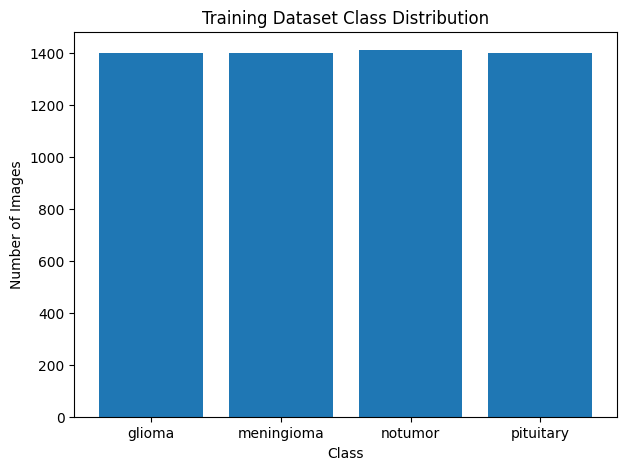

In [ ]:
# class distribution plot

train_counts = [
    len(os.listdir(os.path.join(train_dir, cls)))
    for cls in class_names
]

plt.figure(figsize=(7,5))
plt.bar(class_names, train_counts)

plt.title("Training Dataset Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")

plt.show()

In [ ]:
# The dataset is balanced.(only negligible difference)

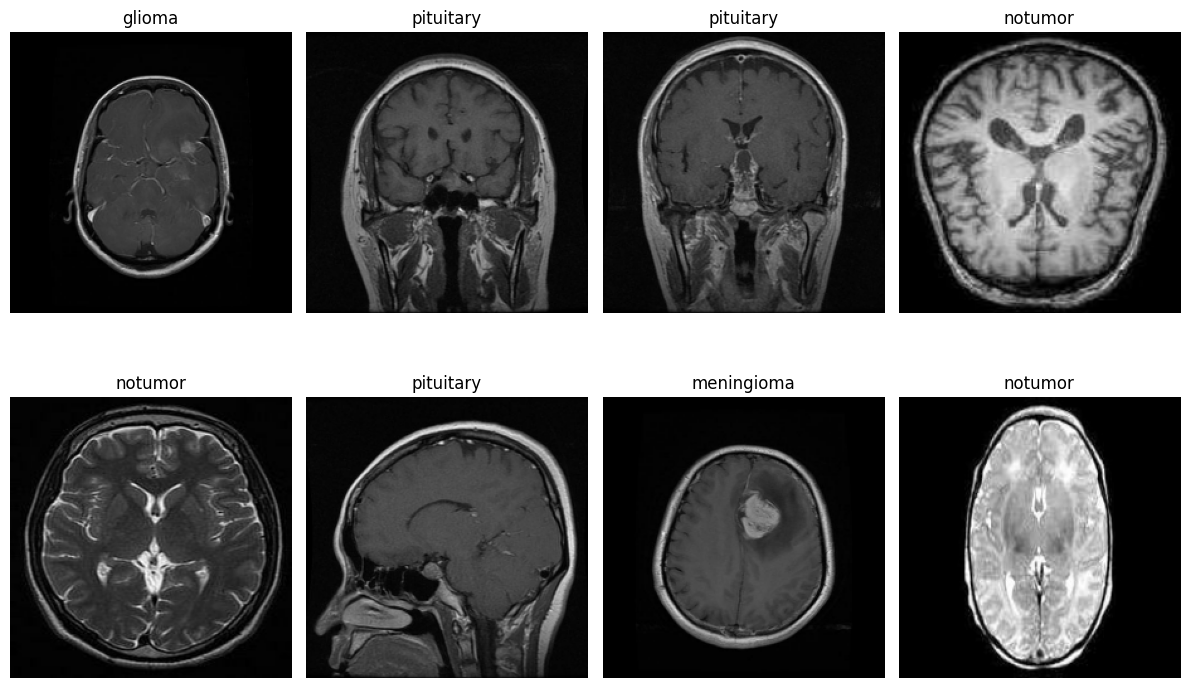

In [ ]:
# Displaying Sample Images
images, labels = next(iter(train_dataset))

plt.figure(figsize=(12,8))

for i in range(8):
    plt.subplot(2,4,i+1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(class_names[labels[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Inference: Ensured that dataset labels corresponded to their respective class folders

In [ ]:
images.shape

TensorShape([32, 224, 224, 3])

# Data Preprocessing

## Normalizing

In [ ]:
# Before normalizing
images, labels = next(iter(train_dataset))
print("Minimum Pixel Value:", images.numpy().min())
print("Maximum Pixel Value:", images.numpy().max())

Minimum Pixel Value: 0.0
Maximum Pixel Value: 255.0


In [ ]:
# Normalizing

normalization_layer = tf.keras.layers.Rescaling(1./255)

train_dataset = train_dataset.map(
    lambda x, y: (normalization_layer(x), y)
)

validation_dataset = validation_dataset.map(
    lambda x, y: (normalization_layer(x), y)
)

test_dataset = test_dataset.map(
    lambda x, y: (normalization_layer(x), y)
)

In [ ]:
# After normalizing
images, labels = next(iter(train_dataset))
print("Minimum Pixel Value:", images.numpy().min())
print("Maximum Pixel Value:", images.numpy().max())

Minimum Pixel Value: 0.0
Maximum Pixel Value: 1.0


In [ ]:
# Inference: The Rescaling(1./255) layer, the pixel values were normalized to the range 0 to 1

## Data Augmentation

In [ ]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1)
])

In [ ]:
# To increases image diversity, some random transformations are applied:

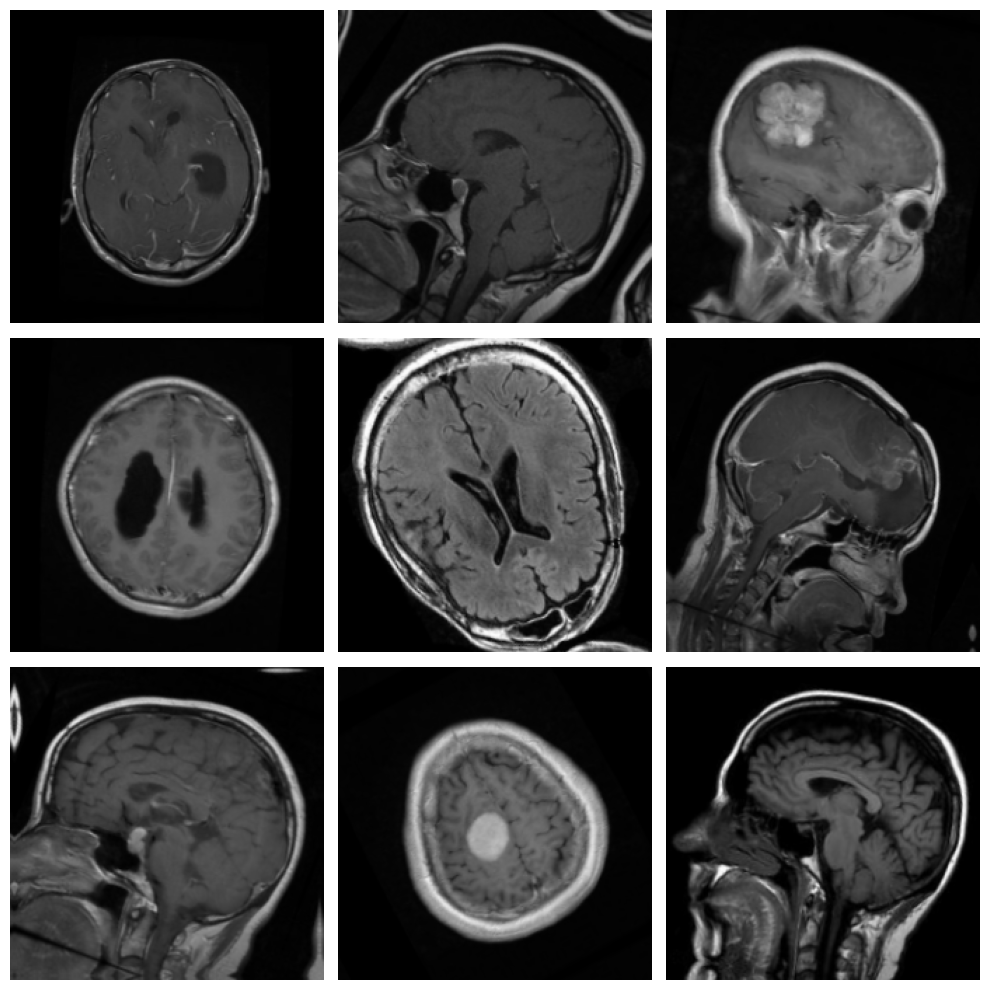

In [ ]:
# Visualize augmented images
images, labels = next(iter(train_dataset))

plt.figure(figsize=(10,10))

for i in range(9):
    augmented_image = data_augmentation(images)[i]

    plt.subplot(3,3,i+1)
    plt.imshow(augmented_image.numpy())
    plt.axis("off")

plt.tight_layout()
plt.show()

# Model Building